# 4-class ablation: baseline, no class weighting, no LLM, no translated CN

Baseline setup for Table 13: class weighting = No, synthetic LLM augmentation = No, translated CN = No.


In [1]:
# Install dependencies (run once)
!pip install transformers datasets torch scikit-learn pandas matplotlib seaborn accelerate sentencepiece -q

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import json
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import set_seed
import os

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support,
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import GroupShuffleSplit
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
)

In [4]:
# =========================
# CONFIG
# =========================
DATA_PATH = "/content/drive/MyDrive/conversation_en.json"
AUGMENTED_TRAIN_PATH = "/content/drive/MyDrive/final_train_augmented_v2_4class.csv"
TRANSLATED_CN_PATH = "/content/drive/MyDrive/conversation_cn_translated_en_deepseek_v4flash.json"

RESULTS_DIR = "/content/drive/MyDrive/intent9Aug/4class_ablation_baseline_noCW_noLLM_noCN"
os.makedirs(RESULTS_DIR, exist_ok=True)

MAX_LEN = 256
RANDOM_STATE = 42
TEST_SIZE = 0.20
VAL_SIZE_WITHIN_TRAIN = 0.20
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
NUM_EPOCHS = 5

VALID_LABELS = ["Chitchat", "Interpret", "Reveal", "Revise"]
label2id = {"Chitchat": 0, "Interpret": 1, "Reveal": 2, "Revise": 3}
id2label = {v: k for k, v in label2id.items()}

print("Labels:", label2id)
print("LR:", LEARNING_RATE, "weight_decay:", WEIGHT_DECAY)
print("Ablation setup: Baseline = class weighting NO, LLM synthetic augmentation NO, translated CN NO")


Labels: {'Chitchat': 0, 'Interpret': 1, 'Reveal': 2, 'Revise': 3}
LR: 2e-05 weight_decay: 0.01
Ablation setup: Baseline = class weighting NO, LLM synthetic augmentation NO, translated CN NO


In [5]:
# =========================
# LOAD ORIGINAL ENGLISH DATA
# =========================
with open(DATA_PATH, "r", encoding="utf-8") as f:
    raw = json.load(f)

all_rows = []
for conv in raw:
    conv_id = str(conv.get("conv_id"))
    for i, t in enumerate(conv.get("conversation", [])):
        all_rows.append({
            "conversation_id": conv_id,
            "turn_index": int(i),
            "role": str(t.get("role", "")).lower(),
            "text": t.get("content") or "",
            "intent": t.get("intent"),
        })

df_turns_full = pd.DataFrame(all_rows).sort_values(
    ["conversation_id", "turn_index"]
).reset_index(drop=True)

df_turns_full["conversation_id"] = df_turns_full["conversation_id"].astype(str)
df_turns_full["turn_index"] = df_turns_full["turn_index"].astype(int)
df_turns_full["role"] = df_turns_full["role"].astype(str).str.lower()
df_turns_full["text"] = df_turns_full["text"].fillna("").astype(str)

target_df = df_turns_full[
    (df_turns_full["role"] == "user") &
    (df_turns_full["intent"].notna()) &
    (df_turns_full["intent"].isin(VALID_LABELS))
].copy().reset_index(drop=True)

turns_by_conv_full = {
    cid: g.sort_values("turn_index").reset_index(drop=True)
    for cid, g in df_turns_full.groupby("conversation_id")
}

print("Original full turn rows:", len(df_turns_full))
print("Original 4-class target rows:", len(target_df))
print("Original conversations:", target_df["conversation_id"].nunique())
print(target_df[["conversation_id", "turn_index", "role", "intent"]].head())

Original full turn rows: 5633
Original 4-class target rows: 3179
Original conversations: 825
  conversation_id  turn_index  role     intent
0          100204           0  user     Reveal
1          100204           2  user     Reveal
2          100325           0  user   Chitchat
3          100325           2  user     Reveal
4          100325           4  user  Interpret


In [6]:
# =========================
#  GROUPED SINGLE SPLIT
# =========================
gss1 = GroupShuffleSplit(
    n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
train_val_idx, test_idx = next(
    gss1.split(target_df, groups=target_df["conversation_id"])
)

train_val_df = target_df.iloc[train_val_idx].reset_index(drop=True)
test_df = target_df.iloc[test_idx].reset_index(drop=True)

gss2 = GroupShuffleSplit(
    n_splits=1, test_size=VAL_SIZE_WITHIN_TRAIN, random_state=RANDOM_STATE
)
train_idx, val_idx = next(
    gss2.split(train_val_df, groups=train_val_df["conversation_id"])
)

train_df_original = train_val_df.iloc[train_idx].reset_index(drop=True)
val_df = train_val_df.iloc[val_idx].reset_index(drop=True)

train_cids = set(train_df_original["conversation_id"].astype(str))
val_cids = set(val_df["conversation_id"].astype(str))
test_cids = set(test_df["conversation_id"].astype(str))

print("Original train rows:", len(train_df_original))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))
print("Train ∩ Val:", len(train_cids & val_cids))
print("Train ∩ Test:", len(train_cids & test_cids))
print("Val ∩ Test:", len(val_cids & test_cids))

assert train_cids.isdisjoint(val_cids)
assert train_cids.isdisjoint(test_cids)
assert val_cids.isdisjoint(test_cids)

#4class original english data split
assert len(train_df_original) == 2014, f"Unexpected train rows: {len(train_df_original)}"
assert len(val_df) == 503, f"Unexpected val rows: {len(val_df)}"
assert len(test_df) == 662, f"Unexpected test rows: {len(test_df)}"



Original train rows: 2014
Validation rows: 503
Test rows: 662
Train ∩ Val: 0
Train ∩ Test: 0
Val ∩ Test: 0


In [7]:
# =========================
# LLM AUGMENTATION DISABLED FOR THIS ABLATION
# =========================
# Ablation condition Baseline:
#   Class weighting: No
#   Synthetic augmentation: No
#   Translated data: No

# Keep empty placeholders so downstream audit variables exist.
aug_all_df = pd.DataFrame()
aug_genuine_df = pd.DataFrame(columns=train_df_original.columns)
aug_train_df = pd.DataFrame(columns=train_df_original.columns)
aug_cids = set()

missing_source_turns = 0
changed_labels = 0

print("LLM synthetic augmentation disabled for this ablation.")
print("Safe LLM augmentation rows retained:", len(aug_train_df))
print("Aug source ∩ Val:", len(aug_cids & val_cids))
print("Aug source ∩ Test:", len(aug_cids & test_cids))
print("Aug source outside Train:", len(aug_cids - train_cids))


LLM synthetic augmentation disabled for this ablation.
Safe LLM augmentation rows retained: 0
Aug source ∩ Val: 0
Aug source ∩ Test: 0
Aug source outside Train: 0


In [8]:
# =========================
# TRANSLATED CN DISABLED FOR THIS ABLATION
# =========================
# Ablation condition Baseline: translated CN data is intentionally OFF.
cn_train_df = pd.DataFrame(columns=train_df_original.columns)
cn_turns_full = pd.DataFrame()
cn_turns_by_conv_full = {}

print("Translated CN disabled for this ablation.")
print("Translated CN rows retained:", len(cn_train_df))


Translated CN disabled for this ablation.
Translated CN rows retained: 0


In [9]:
# =========================
# FINAL TRAIN + LEAKAGE AUDIT
# =========================
# Baseline ablation: original English train only.
# No LLM synthetic data and no translated CN data are added.
train_df = train_df_original.copy().reset_index(drop=True)

print("Final train rows:", len(train_df))
print("  original English:", len(train_df_original))
print("  LLM synthetic augmentation:", 0)
print("  independent translated CN:", 0)
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))
print("\nFinal train label distribution:")
print(train_df["intent"].value_counts())

missing_context_cids = (
    set(train_df["conversation_id"].astype(str)) - set(turns_by_conv_full.keys())
)
print("Missing context conversation IDs:", len(missing_context_cids))
assert len(missing_context_cids) == 0

audit = pd.DataFrame([{
    "ablation_setup": "Baseline: class weighting no, translated CN no, LLM augmentation no",
    "original_train_rows": len(train_df_original),
    "augmentation_csv_rows": 0,
    "genuine_4class_aug_rows": 0,
    "safe_train_source_aug_rows": 0,
    "genuine_aug_rows_excluded_nontrain_source": 0,
    "independent_cn_rows": 0,
    "cn_rows_removed": 0,
    "final_train_rows": len(train_df),
    "val_rows": len(val_df),
    "test_rows": len(test_df),
    "train_val_cid_overlap": len(train_cids & val_cids),
    "train_test_cid_overlap": len(train_cids & test_cids),
    "val_test_cid_overlap": len(val_cids & test_cids),
    "aug_val_source_overlap": 0,
    "aug_test_source_overlap": 0,
    "aug_missing_source_turns": 0,
    "aug_changed_labels": 0,
}])

audit.to_csv(os.path.join(RESULTS_DIR, "leakage_audit_baseline_noCW_noLLM_noCN.csv"), index=False)
display(audit)

assert len(train_cids & val_cids) == 0
assert len(train_cids & test_cids) == 0
assert len(val_cids & test_cids) == 0

print("PASS: Baseline train set uses original English train only; no LLM synthetic or translated CN rows are included.")


Final train rows: 2014
  original English: 2014
  LLM synthetic augmentation: 0
  independent translated CN: 0
Validation rows: 503
Test rows: 662

Final train label distribution:
intent
Interpret    1130
Reveal        673
Chitchat      176
Revise         35
Name: count, dtype: int64
Missing context conversation IDs: 0


,ablation_setup,original_train_rows,augmentation_csv_rows,genuine_4class_aug_rows,safe_train_source_aug_rows,genuine_aug_rows_excluded_nontrain_source,independent_cn_rows,cn_rows_removed,final_train_rows,val_rows,test_rows,train_val_cid_overlap,train_test_cid_overlap,val_test_cid_overlap,aug_val_source_overlap,aug_test_source_overlap,aug_missing_source_turns,aug_changed_labels
0,"Baseline: class weighting no, translated CN no...",2014,0,0,0,0,0,0,2014,503,662,0,0,0,0,0,0,0


PASS: Baseline train set uses original English train only; no LLM synthetic or translated CN rows are included.


In [11]:
 #context builder

def build_context_dataset(df_split, turns_by_conv):
    X, y = [], []
    for _, row in df_split.iterrows():
        cid = str(row["conversation_id"])
        ti = int(row["turn_index"])
        conv_turns = turns_by_conv[cid]
        prev_turns = conv_turns[conv_turns["turn_index"] < ti]

        history = []
        for _, p in prev_turns.iterrows():
            role = str(p["role"]).upper().strip()
            text = str(p["text"]).strip()
            if text:
                history.append(f"{role}: {text}")

        current_turn = str(row["text"]).strip()
        full_text = ("\n".join(history) + "\n" if history else "") + f"USER: {current_turn}"
        X.append(full_text)
        y.append(row["intent"])
    return np.array(X), np.array(y)

X_train, y_train = build_context_dataset(train_df, turns_by_conv_full)
X_val, y_val = build_context_dataset(val_df, turns_by_conv_full)
X_test, y_test = build_context_dataset(test_df, turns_by_conv_full)

print("Context-aware train:", len(X_train))
print("Context-aware val:", len(X_val))
print("Context-aware test:", len(X_test))
print("\nTest distribution:\n", pd.Series(y_test).value_counts())

print("\nTrain distribution:")
print(pd.Series(y_train).value_counts())

print("\nVal distribution:")
print(pd.Series(y_val).value_counts())

print("\nTest distribution:")
print(pd.Series(y_test).value_counts())

# Optional sanity check
revise_indices = [i for i, l in enumerate(y_train) if l == "Revise"]
if revise_indices:
    print("\n--- Sample Revise context (verify SYSTEM turn is present) ---")
    for line in X_train[revise_indices[0]].split("\n"):
        print(" ", line[:110])

Context-aware train: 2014
Context-aware val: 503
Context-aware test: 662

Test distribution:
 Interpret    391
Reveal       197
Chitchat      54
Revise        20
Name: count, dtype: int64

Train distribution:
Interpret    1130
Reveal        673
Chitchat      176
Revise         35
Name: count, dtype: int64

Val distribution:
Interpret    292
Reveal       161
Chitchat      38
Revise        12
Name: count, dtype: int64

Test distribution:
Interpret    391
Reveal       197
Chitchat      54
Revise        20
Name: count, dtype: int64

--- Sample Revise context (verify SYSTEM turn is present) ---
  USER: hello，I want buy a mug
  SYSTEM: how about these？
  USER: ok,the first one i will choose.


In [12]:
cols = ["conversation_id", "turn_index", "role", "text", "intent"]

print("\n--- TRAIN HEAD ---")
print(train_df[cols].head(5))

print("\n--- VAL HEAD ---")
print(val_df[cols].head(5))

print("\n--- TEST HEAD ---")
print(test_df[cols].head(5))


--- TRAIN HEAD ---
  conversation_id  turn_index  role                          text     intent
0          100204           0  user  Hello, I want a Cotton mops.     Reveal
1          100204           2  user                OK, I find it.     Reveal
2          100325           0  user                how r u doing?   Chitchat
3          100325           2  user                 I wanna book!     Reveal
4          100325           4  user                       what!!!  Interpret

--- VAL HEAD ---
  conversation_id  turn_index  role                     text     intent
0          100698           0  user                      hi!   Chitchat
1          100698           2  user         I wanna a plane.  Interpret
2          100698           4  user                     yes!  Interpret
3          100698           6  user   the first one is good!  Interpret
4          101020           0  user  I want to buy a bicycle     Reveal

--- TEST HEAD ---
  conversation_id  turn_index  role              

In [13]:
print(X_train[1])

USER: Hello, I want a Cotton mops.
SYSTEM: Do you find these two satisfactory?
USER: OK, I find it.


In [14]:
# =========================
# LABEL IDS + DISTRIBUTION
# =========================
# Baseline ablation: class weighting is intentionally OFF.
USE_CLASS_WEIGHTS = False
print("Class weighting enabled:", USE_CLASS_WEIGHTS)

y_train_ids = np.array([label2id[x] for x in y_train], dtype=np.int64)
y_val_ids   = np.array([label2id[x] for x in y_val], dtype=np.int64)
y_test_ids  = np.array([label2id[x] for x in y_test], dtype=np.int64)

train_dist = pd.Series(y_train).value_counts(normalize=True)
val_dist   = pd.Series(y_val).value_counts(normalize=True)
test_dist  = pd.Series(y_test).value_counts(normalize=True)

dist_df = pd.DataFrame({
    "train_%": train_dist,
    "val_%": val_dist,
    "test_%": test_dist,
}).reindex(VALID_LABELS).fillna(0)

print("Label distribution (%):")
print(dist_df)

classes = np.arange(len(VALID_LABELS))
missing = set(classes) - set(np.unique(y_train_ids))
assert not missing, f"Missing train classes: {[id2label[i] for i in sorted(missing)]}"

print("Class weights: OFF for this ablation")


Class weighting enabled: False
Label distribution (%):
            train_%     val_%    test_%
Chitchat   0.087388  0.075547  0.081571
Interpret  0.561072  0.580517  0.590634
Reveal     0.334161  0.320080  0.297583
Revise     0.017378  0.023857  0.030211
Class weights: OFF for this ablation


In [15]:
# ── Standard Trainer metrics ─────────────────────────────────
from transformers import Trainer
import numpy as np
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    p, r, f1, _ = precision_recall_fscore_support(
        labels, preds, average="macro", zero_division=0
    )
    acc = accuracy_score(labels, preds)

    return {
        "accuracy": acc,
        "macro_precision": p,
        "macro_recall": r,
        "macro_f1": f1,
    }

print("Standard Trainer metrics defined. Class weights are OFF.")


Standard Trainer metrics defined. Class weights are OFF.


In [16]:
# ── Helper: tokenize + build HF Datasets ────────────────────
from datasets import Dataset

def make_hf_datasets(tokenizer, X_tr, y_tr_ids, X_val, y_val_ids, X_te, y_te_ids):
    tr_enc  = tokenizer(list(X_tr),  truncation=True, padding=True, max_length=MAX_LEN)
    val_enc = tokenizer(list(X_val), truncation=True, padding=True, max_length=MAX_LEN)
    te_enc  = tokenizer(list(X_te),  truncation=True, padding=True, max_length=MAX_LEN)

    train_ds = Dataset.from_dict({
        "input_ids": tr_enc["input_ids"],
        "attention_mask": tr_enc["attention_mask"],
        "labels": list(y_tr_ids),
    })

    val_ds = Dataset.from_dict({
        "input_ids": val_enc["input_ids"],
        "attention_mask": val_enc["attention_mask"],
        "labels": list(y_val_ids),
    })

    test_ds = Dataset.from_dict({
        "input_ids": te_enc["input_ids"],
        "attention_mask": te_enc["attention_mask"],
        "labels": list(y_te_ids),
    })

    return train_ds, val_ds, test_ds


# ── Helper: learning curve ────────────────────────────────────
def plot_learning_curve(trainer, model_name):
    logs = trainer.state.log_history
    train_entries = [l for l in logs if "loss" in l and "eval_loss" not in l]
    eval_entries = [l for l in logs if "eval_loss" in l]

    if not eval_entries:
        print("No eval logs found — skipping learning curve.")
        return

    epochs_train = [l["epoch"] for l in train_entries]
    loss_train = [l["loss"] for l in train_entries]
    epochs_eval = [l["epoch"] for l in eval_entries]
    loss_eval = [l["eval_loss"] for l in eval_entries]
    f1_eval = [l.get("eval_macro_f1") for l in eval_entries]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(f"Learning Curve — {model_name}", fontsize=13)

    axes[0].plot(epochs_train, loss_train, marker="o", label="Train loss")
    axes[0].plot(epochs_eval, loss_eval, marker="s", label="Val loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title("Loss per epoch")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    if any(v is not None for v in f1_eval):
        axes[1].plot(epochs_eval, f1_eval, marker="s", color="green", label="Val macro-F1")
        axes[1].set_xlabel("Epoch")
        axes[1].set_ylabel("Macro F1")
        axes[1].set_title("Macro F1 per epoch")
        axes[1].legend()
        axes[1].grid(True, alpha=0.3)
        axes[1].set_ylim(0, 1)
    else:
        axes[1].set_visible(False)

    plt.tight_layout()
    fname = f"{model_name.lower().replace('/', '_')}_learning_curve.png"
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {fname}")

In [17]:
# ── Helper: evaluate + report ────────────────────────────────
def evaluate_and_report(trainer, dataset, y_ids, X_texts, split_name, model_name):
    pred_out = trainer.predict(dataset)
    y_pred_ids = np.argmax(pred_out.predictions, axis=1)

    y_pred = [id2label[i] for i in y_pred_ids]
    y_true = [id2label[i] for i in y_ids]

    report = classification_report(
        y_true,
        y_pred,
        labels=VALID_LABELS,
        digits=3,
        zero_division=0,
    )

    print(f"\n=== {model_name} — {split_name} CLASSIFICATION REPORT ===")
    print(report)

    cm = confusion_matrix(y_true, y_pred, labels=VALID_LABELS)

    cm_df = pd.DataFrame(
        cm,
        index=[f"true_{l}" for l in VALID_LABELS],
        columns=[f"pred_{l}" for l in VALID_LABELS],
    )

    print(f"\n=== {model_name} — {split_name} CONFUSION MATRIX ===")
    print(cm_df)

    # Compact numeric metrics for paper tables
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=VALID_LABELS,
        average="macro",
        zero_division=0,
    )

    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=VALID_LABELS,
        average="weighted",
        zero_division=0,
    )

    acc = accuracy_score(y_true, y_pred)

    _, _, per_class_f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=VALID_LABELS,
        average=None,
        zero_division=0,
    )

    metrics = {
        "split": split_name.upper(),
        "model": model_name,
        "accuracy": acc,
        "macro_precision": macro_p,
        "macro_recall": macro_r,
        "macro_f1": macro_f1,
        "weighted_precision": weighted_p,
        "weighted_recall": weighted_r,
        "weighted_f1": weighted_f1,
        "samples": len(y_true),
    }

    for label, f1_val, supp in zip(VALID_LABELS, per_class_f1, support):
        metrics[f"{label.lower()}_f1"] = f1_val
        metrics[f"{label.lower()}_support"] = supp

    tag = f"{model_name.lower().replace('/', '_')}_{split_name.lower()}"

    # Save confusion matrix image
    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=VALID_LABELS,
        yticklabels=VALID_LABELS,
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix — {model_name} ({split_name})")
    plt.tight_layout()

    plt.savefig(
        os.path.join(RESULTS_DIR, f"{tag}_cm.png"),
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

    # Save predictions
    pred_df = pd.DataFrame({
        "text": X_texts,
        "true_label": y_true,
        "predicted_label": y_pred,
    })

    pred_df.to_csv(
        os.path.join(RESULTS_DIR, f"{tag}_predictions.csv"),
        index=False,
    )

    # Misclassified examples
    errors = pred_df[pred_df["true_label"] != pred_df["predicted_label"]]

    confused_pairs = (
        errors[["true_label", "predicted_label"]]
        .value_counts()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
    )

    if split_name.upper() in ["VAL", "TEST"]:

        print(f"\n=== {model_name} {split_name} TOP CONFUSED PAIRS ===")
        display(confused_pairs.head(15))

        print(f"\n=== {model_name} {split_name} SAMPLE MISCLASSIFIED EXAMPLES ===")
        display(errors.head(15))

        errors.to_csv(
            os.path.join(RESULTS_DIR, f"{tag}_misclassified.csv"),
            index=False,
        )

        confused_pairs.to_csv(
            os.path.join(RESULTS_DIR, f"{tag}_confused_pairs.csv"),
            index=False,
        )

    # Save text report
    with open(
        os.path.join(RESULTS_DIR, f"{tag}_report.txt"),
        "w",
        encoding="utf-8",
    ) as f:

        f.write(f"=== {model_name} — {split_name} CLASSIFICATION REPORT ===\n")
        f.write(report)

        f.write("\n\n=== CONFUSION MATRIX ===\n")
        f.write(cm_df.to_string())

        f.write("\n\n=== COMPACT METRICS ===\n")
        f.write(pd.DataFrame([metrics]).to_string(index=False))

        if split_name.upper() in ["VAL", "TEST"]:
            f.write("\n\n=== TOP CONFUSED PAIRS ===\n")
            f.write(confused_pairs.head(15).to_string(index=False))

            f.write("\n\n=== SAMPLE MISCLASSIFIED EXAMPLES ===\n")
            f.write(errors.head(15).to_string(index=False))

    return pred_df, cm_df, confused_pairs, errors, metrics


print("All helpers defined.")

All helpers defined.


In [18]:
# ── Master helper: train one model end-to-end ────────────────
def run_model(model_name, num_epochs=5):
    """
    1. Tokenize with the model's own tokenizer
    2. Train with standard Trainer using TRAIN data
    3. Select best checkpoint using VAL macro-F1
    4. Plot learning curve
    5. Evaluate on TRAIN, VAL, and TEST
    """
    print("\n" + "=" * 65)
    print(f"  MODEL: {model_name}")
    print("=" * 65)

    set_seed(RANDOM_STATE)

    use_fast = False if "deberta-v3" in model_name else True
    tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=use_fast)

    train_ds, val_ds, test_ds = make_hf_datasets(
        tokenizer,
        X_train, y_train_ids,
        X_val, y_val_ids,
        X_test, y_test_ids,
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=len(VALID_LABELS),
        id2label=id2label,
        label2id=label2id,
    )

    short_name = model_name.split("/")[-1]

    training_args = TrainingArguments(
        output_dir=os.path.join(RESULTS_DIR, f"{short_name}_results"),
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        num_train_epochs=num_epochs,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        seed=RANDOM_STATE,
        data_seed=RANDOM_STATE,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        report_to="none",
        fp16=torch.cuda.is_available() and "deberta-v3" not in model_name,
        save_total_limit=2,
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        compute_metrics=compute_metrics,
    )

    trainer.train()
    print("Best checkpoint:", trainer.state.best_model_checkpoint)
    print("Best validation macro-F1:", trainer.state.best_metric)

    plot_learning_curve(trainer, short_name)

    evaluate_and_report(
        trainer,
        train_ds,
        y_train_ids,
        X_train,
        split_name="TRAIN",
        model_name=short_name,
    )

    evaluate_and_report(
        trainer,
        val_ds,
        y_val_ids,
        X_val,
        split_name="VAL",
        model_name=short_name,
    )

    test_pred_df, test_cm_df, test_confused_pairs, test_errors, test_metrics = evaluate_and_report(
        trainer,
        test_ds,
        y_test_ids,
        X_test,
        split_name="TEST",
        model_name=short_name,
    )

    return trainer, test_metrics

print("run_model() defined for baseline no-weight ablation.")


run_model() defined for baseline no-weight ablation.


## DistilBERT

In [19]:
# Disabled for this BERT-only ablation notebook.


## RoBERTa-base

In [20]:
# Disabled for this BERT-only ablation notebook.


## BERT-base-uncased


  MODEL: bert-base-uncased


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best checkpoint: /content/drive/MyDrive/intent9Aug/4class_ablation_baseline_noCW_noLLM_noCN/bert-base-uncased_results/checkpoint-756
Best validation macro-F1: 0.6276413620057328


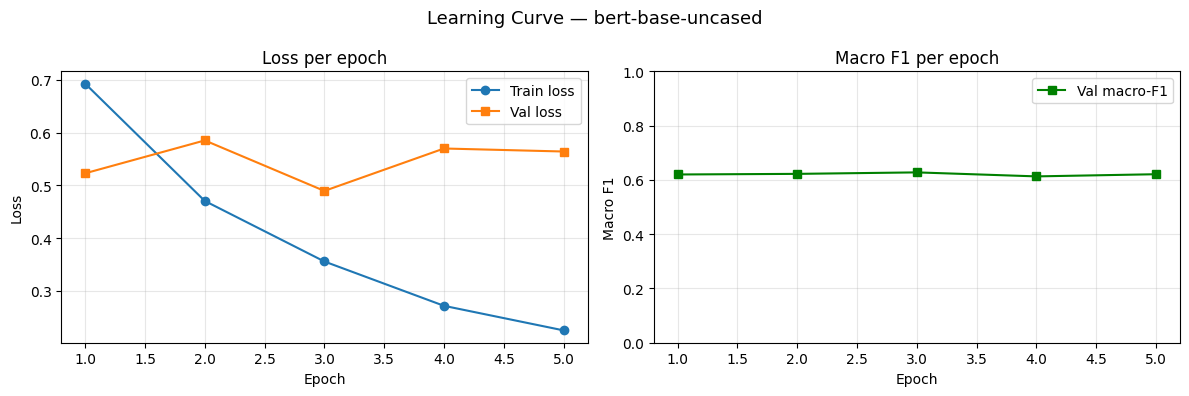

Saved: bert-base-uncased_learning_curve.png



=== bert-base-uncased — TRAIN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.895     0.483     0.627       176
   Interpret      0.940     0.990     0.965      1130
      Reveal      0.903     0.978     0.939       673
      Revise      0.000     0.000     0.000        35

    accuracy                          0.925      2014
   macro avg      0.684     0.613     0.633      2014
weighted avg      0.907     0.925     0.910      2014


=== bert-base-uncased — TRAIN CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              85              37           54            0
true_Interpret              4            1119            7            0
true_Reveal                 6               9          658            0
true_Revise                 0              25           10            0


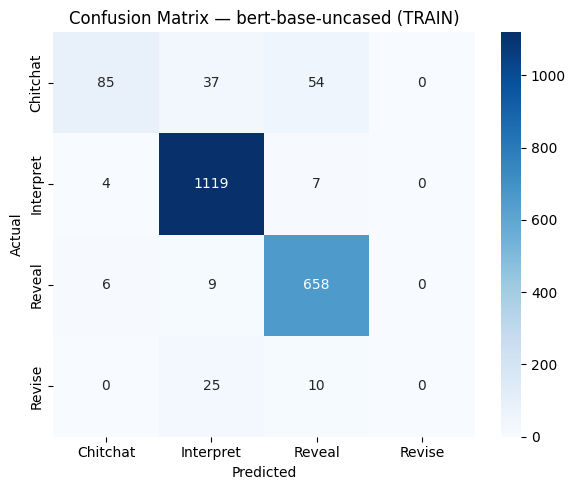


=== bert-base-uncased — VAL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.958     0.605     0.742        38
   Interpret      0.886     0.928     0.906       292
      Reveal      0.832     0.894     0.862       161
      Revise      0.000     0.000     0.000        12

    accuracy                          0.871       503
   macro avg      0.669     0.607     0.628       503
weighted avg      0.853     0.871     0.858       503


=== bert-base-uncased — VAL CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              23              10            5            0
true_Interpret              1             271           20            0
true_Reveal                 0              17          144            0
true_Revise                 0               8            4            0


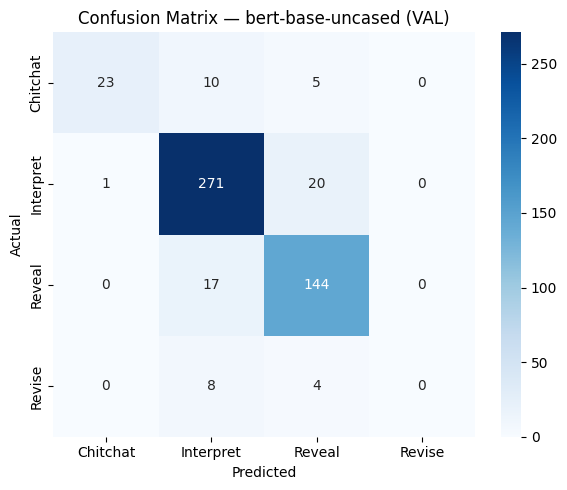


=== bert-base-uncased VAL TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Interpret,Reveal,20
1,Reveal,Interpret,17
2,Chitchat,Interpret,10
3,Revise,Interpret,8
4,Chitchat,Reveal,5
5,Revise,Reveal,4
6,Interpret,Chitchat,1



=== bert-base-uncased VAL SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a plane.,Interpret,Reveal
5,USER: I want to buy a bicycle\nSYSTEM: How abo...,Revise,Reveal
8,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Interpret
14,"USER: Show me some stylish, lightweight Compac...",Interpret,Reveal
15,"USER: Show me some stylish, lightweight Compac...",Reveal,Interpret
18,USER: I want a Collapsible Water Bottle\nSYSTE...,Interpret,Reveal
19,USER: I want a Collapsible Water Bottle\nSYSTE...,Interpret,Reveal
21,"USER: hi,I want a phone\nSYSTEM: What size of ...",Interpret,Reveal
38,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret
39,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret



=== bert-base-uncased — TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.946     0.648     0.769        54
   Interpret      0.886     0.954     0.919       391
      Reveal      0.833     0.863     0.848       197
      Revise      0.000     0.000     0.000        20

    accuracy                          0.873       662
   macro avg      0.666     0.616     0.634       662
weighted avg      0.848     0.873     0.858       662


=== bert-base-uncased — TEST CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              35              11            8            0
true_Interpret              1             373           17            0
true_Reveal                 1              26          170            0
true_Revise                 0              11            9            0


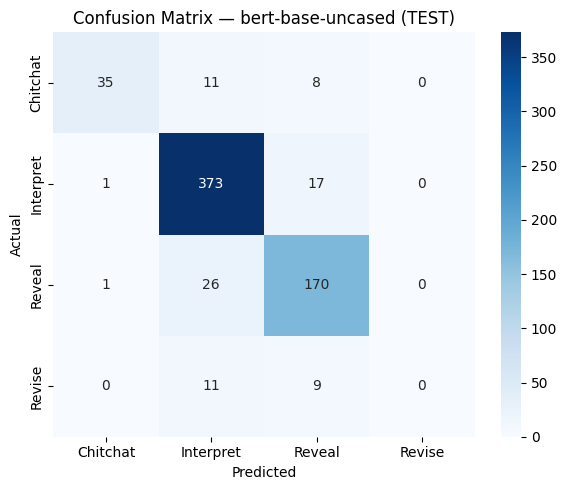


=== bert-base-uncased TEST TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,26
1,Interpret,Reveal,17
2,Revise,Interpret,11
3,Chitchat,Interpret,11
4,Revise,Reveal,9
5,Chitchat,Reveal,8
6,Interpret,Chitchat,1
7,Reveal,Chitchat,1



=== bert-base-uncased TEST SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
2,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Interpret
8,USER: I want to buy an electronic lock\nSYSTEM...,Interpret,Reveal
10,USER: I want a cotton slippers.\nSYSTEM: do yo...,Reveal,Interpret
14,USER: I want to buy a school bag\nSYSTEM: what...,Chitchat,Interpret
20,"USER: I want to buy a lightweight laptop, main...",Revise,Reveal
22,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
23,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
27,"USER: I’m looking for a smartwatch for kids, w...",Revise,Interpret
32,"USER: I want some scented candles\nSYSTEM: ok,...",Interpret,Reveal
38,USER: Please recommend me a baby stroller\nSYS...,Reveal,Interpret


,Setup,Class_weighting,Synthetic_augmentation,Translated_data,Model,Seed,Accuracy,Macro_F1,Weighted_F1,Chitchat_F1,Interpret_F1,Reveal_F1,Revise_F1,Test_samples
0,Baseline,No,No,No,BERT-base,42,0.873112,0.633958,0.857689,0.769231,0.918719,0.84788,0.0,662


Saved manuscript-ready Baseline ablation row.


In [21]:
# =========================
# RUN BERT BASE ONLY FOR BASELINE ABLATION
# =========================
bert_trainer, bert_test_metrics = run_model("bert-base-uncased", num_epochs=NUM_EPOCHS)

ablation_result = pd.DataFrame([{
    "Setup": "Baseline",
    "Class_weighting": "No",
    "Synthetic_augmentation": "No",
    "Translated_data": "No",
    "Model": "BERT-base",
    "Seed": RANDOM_STATE,
    "Accuracy": bert_test_metrics["accuracy"],
    "Macro_F1": bert_test_metrics["macro_f1"],
    "Weighted_F1": bert_test_metrics["weighted_f1"],
    "Chitchat_F1": bert_test_metrics.get("chitchat_f1"),
    "Interpret_F1": bert_test_metrics.get("interpret_f1"),
    "Reveal_F1": bert_test_metrics.get("reveal_f1"),
    "Revise_F1": bert_test_metrics.get("revise_f1"),
    "Test_samples": bert_test_metrics["samples"],
}])

display(ablation_result)
ablation_result.to_csv(
    os.path.join(RESULTS_DIR, "ablation_baseline_noCW_noLLM_noCN_BERT_result.csv"),
    index=False,
)
print("Saved manuscript-ready Baseline ablation row.")


## MiniLM

In [22]:
# Disabled for this BERT-only ablation notebook.


## DeBERTa-v3-base

> **Note:** Run the cell below before this model if sentencepiece is not installed.
> ```
> !pip install sentencepiece -q
> ```

In [23]:
#!pip install sentencepiece -q


In [24]:
# Disabled for this BERT-only ablation notebook.


**Inference check**

In [25]:
# Disabled for this BERT-only ablation notebook.


In [26]:
# Disabled for this BERT-only ablation notebook.
